## Olist E-Commerce: Data Exploration with DuckDB

## 1. Setup the notebook

In this notebook we load five tables of the e-commerce dataset into DuckDB and explore them with SQL before designing a data warehouse.

**What we will do**

1. Load the CSV files into DuckDB
2. Understand each table: structure, grain, keys
3. Check the relationships (foreign keys)
4. Find data quality issues
5. Build a star schema

**Tables:** `customers`, `orders`, `order_items`, `products`, `sellers`

In [3]:
from pathlib import Path

import duckdb
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
ROOT = Path.cwd().parent
DATA_DIR = ROOT / "data"
RAW_DIR = DATA_DIR / "raw"
WAREHOUSE_DIR = DATA_DIR / "warehouse"
csv = RAW_DIR / "olist_orders_dataset.csv"

In [5]:
print(duckdb.sql(f"SELECT count(*) FROM '{csv}'"))

┌──────────────┐
│ count_star() │
│    int64     │
├──────────────┤
│        99441 │
└──────────────┘



### DuckDB lets query CSV data with SQL. The database file persists locally so later notebooks can reuse the loaded raw tables.

In [11]:
WAREHOUSE_DIR.mkdir(parents=True, exist_ok=True)
print("Warehouse folder created:", WAREHOUSE_DIR)

DB_PATH = WAREHOUSE_DIR / "ecommerce.duckdb"
con = duckdb.connect(str(DB_PATH))


Warehouse folder created: C:\Users\HP\Documents\kddm_lab\data\warehouse


In [13]:
def q(sql_str: str) -> pd.DataFrame:
    """Run a SQL query in DuckDB and return a pandas DataFrame."""
    return con.sql(sql_str).df()

## 2. Load the source tables into a **raw schema**

A Schema is a namespace that groups tables. We keep the source copies in **raw**
so that they remain distinguishable from cleaned warehouse tables we will create later.

### Define a mapping to transform column types

In [15]:
RAW_TABLES: dict[str, dict[str, str]] = {
    "customers": {"customer_zip_code_prefix": "VARCHAR"},  # keep leading zeros
    "orders": {},
    "order_items": {},
    "products": {},
    "sellers": {}
}

### Define some helper functions

In [16]:
def csv_path(table: str) -> Path:
    """"""
    return RAW_DIR / f"olist_{table}_dataset.csv"

def check_source_files(tables) -> None:
    """Fail once, list every missing file"""
    missing = [csv_path(t) for t in tables if not csv_path(t).exists()]
    if missing:
        names = "\n".join(f" - {p}" for p in missing)
        raise FileNotFoundError(f"Missing CSV files: {names}")

#### Define schema name for source data

In [17]:
RAW_SCHEMA = "raw"

### Load data into source tables

In [21]:
def load_raw_table(con: duckdb.DuckDBPyConnection, table: str, column_types: dict[str, str]) -> int:
    target = f'{RAW_SCHEMA}."{table}"'
    source = con.read_csv(str(csv_path(table)), header=True, dtype=column_types or None)
    con.execute(f"DROP TABLE IF EXISTS {target}")
    source.to_table(target)
    return con.execute(f"SELECT count(*) FROM {target}").fetchone()[0]

### Sanity check if we have all required source files

In [26]:
check_source_files(RAW_TABLES)

### Create **RAW_SCHEMA** if it does not exist

In [27]:
con.execute(f"CREATE SCHEMA IF NOT EXISTS {RAW_SCHEMA}")

### Execute **load_raw_table** to load all source data

In [29]:
row_counts = {t: load_raw_table(con, t, types) for t, types in RAW_TABLES.items()}

row_counts = {
    t: load_raw_table(con, t, types)
    for t, types in RAW_TABLES.items()
}

### Check count of rows inserted into each `raw`.`<table>`

In [30]:
pd.DataFrame(row_counts.items(), columns=["table_name", "row_count"])

,table_name,row_count
0,customers,99441
1,orders,99441
2,order_items,112650
3,products,32951
4,sellers,3095


## 3. Look at each table

For every table we ask: **what does one row represent?** This is the *grain*. Getting the grain right is the most important step in dimensional modeling.

In [28]:
for t in RAW_TABLES:
    print(f"----- {t} -----")
    display(q(f"DESCRIBE raw.{t}")[["column_name", "column_type", "null"]])
    display(q(f"SELECT * FROM raw.{t} LIMIT 3"))

----- customers -----


,column_name,column_type,null
0,customer_id,VARCHAR,YES
1,customer_unique_id,VARCHAR,YES
2,customer_zip_code_prefix,VARCHAR,YES
3,customer_city,VARCHAR,YES
4,customer_state,VARCHAR,YES


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,09790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,01151,sao paulo,SP


----- orders -----


,column_name,column_type,null
0,order_id,VARCHAR,YES
1,customer_id,VARCHAR,YES
2,order_status,VARCHAR,YES
3,order_purchase_timestamp,TIMESTAMP,YES
4,order_approved_at,TIMESTAMP,YES
5,order_delivered_carrier_date,TIMESTAMP,YES
6,order_delivered_customer_date,TIMESTAMP,YES
7,order_estimated_delivery_date,TIMESTAMP,YES


...

,column_name,column_type,null
0,product_id,VARCHAR,YES
1,product_category_name,VARCHAR,YES
2,product_name_lenght,BIGINT,YES
3,product_description_lenght,BIGINT,YES
4,product_photos_qty,BIGINT,YES
5,product_weight_g,BIGINT,YES
6,product_length_cm,BIGINT,YES
7,product_height_cm,BIGINT,YES
8,product_width_cm,BIGINT,YES


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40,287,1,225,16,10,14
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44,276,1,1000,30,18,20
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46,250,1,154,18,9,15


----- sellers -----


,column_name,column_type,null
0,seller_id,VARCHAR,YES
1,seller_zip_code_prefix,VARCHAR,YES
2,seller_city,VARCHAR,YES
3,seller_state,VARCHAR,YES


,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ


`SUMMARIZE`profiles every column is one command: min, max, average, null percentage,
approximate distinct count.

In [31]:
q("SUMMARIZE raw.order_items")

,column_name,column_type,min,max,approx_unique,avg,std,q25,q50,q75,count,null_percentage
0,order_id,VARCHAR,00010242fe8c5a6d1ba2dd792cb16214,fffe41c64501cc87c801fd61db3f6244,87618,NaN,NaN,NaN,NaN,NaN,112650,0.0
1,order_item_id,BIGINT,1,21,21,1.1978339991122948,0.7051240313951734,1,1,1,112650,0.0
2,product_id,VARCHAR,00066f42aeeb9f3007548bb9d3f33c38,fffe9eeff12fcbd74a2f2b007dde0c58,24292,NaN,NaN,NaN,NaN,NaN,112650,0.0
3,seller_id,VARCHAR,0015a82c2db000af6aaaf3ae2ecb0532,ffff564a4f9085cd26170f4732393726,3886,NaN,NaN,NaN,NaN,NaN,112650,0.0
4,shipping_limit_date,TIMESTAMP,2016-09-19 00:15:34,2020-04-09 22:35:08,80774,2018-01-07 15:36:52.192685,NaN,2017-09-20 14:24:06.919554,2018-01-27 19:47:01.503972,2018-05-11 00:22:53.928243,112650,0.0
5,price,DOUBLE,0.85,6735.0,6497,120.65373901477311,183.6339280502597,40.01666999532123,74.5760959518914,134.19097071958893,112650,0.0
6,freight_value,DOUBLE,0.0,409.68,5665,19.99031992898562,15.806405412296998,13.071531156591233,16.279508106244663,21.16306476327699,112650,0.0


In [32]:
q("SUMMARIZE raw.order_items")

,column_name,column_type,min,max,approx_unique,avg,std,q25,q50,q75,count,null_percentage
0,order_id,VARCHAR,00010242fe8c5a6d1ba2dd792cb16214,fffe41c64501cc87c801fd61db3f6244,87618,NaN,NaN,NaN,NaN,NaN,112650,0.0
1,order_item_id,BIGINT,1,21,21,1.1978339991122948,0.7051240313951734,1,1,1,112650,0.0
2,product_id,VARCHAR,00066f42aeeb9f3007548bb9d3f33c38,fffe9eeff12fcbd74a2f2b007dde0c58,24292,NaN,NaN,NaN,NaN,NaN,112650,0.0
3,seller_id,VARCHAR,0015a82c2db000af6aaaf3ae2ecb0532,ffff564a4f9085cd26170f4732393726,3886,NaN,NaN,NaN,NaN,NaN,112650,0.0
4,shipping_limit_date,TIMESTAMP,2016-09-19 00:15:34,2020-04-09 22:35:08,80774,2018-01-07 15:36:52.192685,NaN,2017-09-20 14:24:06.919554,2018-01-27 19:47:01.503972,2018-05-11 00:22:53.928243,112650,0.0
5,price,DOUBLE,0.85,6735.0,6497,120.65373901477311,183.6339280502597,40.01666999532123,74.5760959518914,134.19097071958893,112650,0.0
6,freight_value,DOUBLE,0.0,409.68,5665,19.99031992898562,15.806405412296998,13.071531156591233,16.279508106244663,21.16306476327699,112650,0.0


In [33]:
q("SUMMARIZE raw.products")

,column_name,column_type,min,max,approx_unique,avg,std,q25,q50,q75,count,null_percentage
0,product_id,VARCHAR,00066f42aeeb9f3007548bb9d3f33c38,fffe9eeff12fcbd74a2f2b007dde0c58,24292,NaN,NaN,NaN,NaN,NaN,32951,0.00
1,product_category_name,VARCHAR,agro_industria_e_comercio,utilidades_domesticas,66,NaN,NaN,NaN,NaN,NaN,32951,1.85
2,product_name_lenght,BIGINT,5,76,64,48.47694876472589,10.245740725237287,42,51,57,32951,1.85
3,product_description_lenght,BIGINT,4,3992,2781,771.4952846232337,635.1152246349538,339,594,973,32951,1.85
4,product_photos_qty,BIGINT,1,20,20,2.1889861166939797,1.7367656379315435,1,1,3,32951,1.85
5,product_weight_g,BIGINT,0,40425,2155,2276.4724877841513,4282.038730977024,300,701,1883,32951,0.01
6,product_length_cm,BIGINT,7,105,97,30.81507784758263,16.914458054065953,18,25,39,32951,0.01
7,product_height_cm,BIGINT,2,105,99,16.937661234028347,13.637554061749569,8,13,21,32951,0.01
8,product_width_cm,BIGINT,6,118,92,23.196728277034204,12.079047453227794,15,20,30,32951,0.01


## 4. Primary Keys

A **primary key** uniquely identifies a row. A column is a valid candidate only if `count(*) = count(distinct ...)` and it has no nulls.

- A **composite key** uses several columns together (`order_items`)
- A **natural key** comes from the business (`customer_unique_id`).
- A **surrogate key** is generated by the warehouse (`customer_key = 1, 2, 3...`)

In [34]:
q("""
SELECT 'customers.customer_id'         AS candidate, count(*) AS n, count(DISTINCT customer_id) AS n_distinct FROM raw.customers
UNION ALL SELECT 'customers.customer_unique_id',         count(*), count(DISTINCT customer_unique_id) FROM raw.customers
UNION ALL SELECT 'orders.order_id',                      count(*), count(DISTINCT order_id) FROM raw.orders
UNION ALL SELECT 'order_items.order_id (alone)',         count(*), count(DISTINCT order_id) FROM raw.order_items
UNION ALL SELECT 'order_items(order_id, order_item_id)', count(*), count(DISTINCT (order_id, order_item_id)) FROM raw.order_items
UNION ALL SELECT 'products.product_id',                  count(*), count(DISTINCT product_id) FROM raw.products
UNION ALL SELECT 'sellers.seller_id',                    count(*), count(DISTINCT seller_id) FROM raw.sellers
""")

,candidate,n,n_distinct
0,customers.customer_id,99441,99441
1,customers.customer_unique_id,99441,96096
2,orders.order_id,99441,99441
3,order_items.order_id (alone),112650,98666
4,"order_items(order_id, order_item_id)",112650,112650
5,products.product_id,32951,32951
6,sellers.seller_id,3095,3095


## 4. Foreign key relationships

```
customers 1 ---- N orders 1 ---- N order_items N ---- 1 products
```

A foreign key is healthy when every value exists in the parent table. An **orphan** is
a child row with no parent.

In [35]:
q("""
SELECT 'orders without customer' AS check_name, count(*) AS n
  FROM raw.orders o ANTI JOIN raw.customers c USING (customer_id)
UNION ALL SELECT 'items without order', count(*)
  FROM raw.order_items i ANTI JOIN raw.orders o USING (order_id)
UNION ALL SELECT 'items without product', count(*)
  FROM raw.order_items i ANTI JOIN raw.products p USING (product_id)
UNION ALL SELECT 'items without seller', count(*)
    FROM raw.order_items i ANTI JOIN raw.sellers s USING (seller_id)
UNION ALL SELECT 'orders without items', count(*)
  FROM raw.orders o ANTI JOIN raw.order_items i USING (order_id)
""")

,check_name,n
0,orders without customer,0
1,items without order,0
2,items without product,0
3,items without seller,0
4,orders without items,775


No orphans in the child-to-parent direction. But 775 orders have no items. An **INNER JOIN** from orders
to items would silently remove them.

## 5. Data Quality

we check five dimensions: completeness(nulls), uniqueness, validity (values in a sensible range),
consistency (fields agree), timeliness (coverage)

### 5.1 Orders with no items

#### Exercise 1

In [15]:

q("""\
SELECT
    o.order_id,
    o.order_status
FROM raw.orders AS o
ANTI JOIN raw.order_items AS oi
    ON o.order_id = oi.order_id
""")


,order_id,order_status
0,8e24261a7e58791d10cb1bf9da94df5c,unavailable
1,c272bcd21c287498b4883c7512019702,unavailable
2,37553832a3a89c9b2db59701c357ca67,unavailable
3,d57e15fb07fd180f06ab3926b39edcd2,unavailable
4,00b1cb0320190ca0daa2c88b35206009,canceled
...,...,...
770,aaab15da689073f8f9aa978a390a69d1,unavailable
771,3a3cddda5a7c27851bd96c3313412840,canceled
772,a89abace0dcc01eeb267a9660b5ac126,canceled
773,a69ba794cc7deb415c3e15a0a3877e69,unavailable


### 5.2 Check order status and class imbalance

#### Exercise 2

In [16]:

q("""\
SELECT
    order_status,
    COUNT(*) AS order_count
FROM raw.orders
GROUP BY order_status
ORDER BY order_count DESC
""")


,order_status,order_count
0,delivered,96478
1,shipped,1107
2,canceled,625
3,unavailable,609
4,invoiced,314
5,processing,301
6,created,5
7,approved,2


### 5.3 Missing and inconsistent timestamps

#### Exercise 3

In [17]:

q("""\
SELECT
    COUNT(*) FILTER (
        WHERE order_approved_at IS NULL
    ) AS approved_null,

    COUNT(*) FILTER (
        WHERE order_delivered_carrier_date IS NULL
    ) AS carrier_null,

    COUNT(*) FILTER (
        WHERE order_delivered_customer_date IS NULL
    ) AS delivered_null,

    COUNT(*) FILTER (
        WHERE order_status = 'delivered'
          AND order_delivered_customer_date IS NULL
    ) AS delivered_but_no_date,

    COUNT(*) FILTER (
        WHERE order_delivered_carrier_date >
              order_delivered_customer_date
    ) AS carrier_after_customer,

    COUNT(*) FILTER (
        WHERE order_approved_at < order_purchase_timestamp
    ) AS approved_before_purchase

FROM raw.orders
""")


,approved_null,carrier_null,delivered_null,delivered_but_no_date,carrier_after_customer,approved_before_purchase
0,160,1783,2965,8,23,0


### 5.4 Time coverage

#### Exercise 4

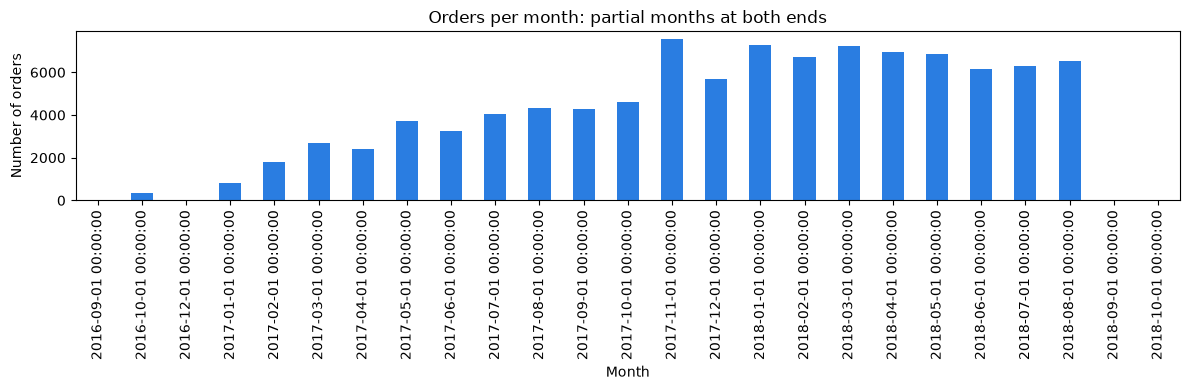

In [19]:

monthly = q("""\
SELECT
    DATE_TRUNC('month', order_purchase_timestamp) AS month,
    COUNT(*) AS orders
FROM raw.orders
WHERE order_purchase_timestamp IS NOT NULL
GROUP BY DATE_TRUNC('month', order_purchase_timestamp)
ORDER BY month
""")

ax = monthly.plot.bar(
    x="month",
    y="orders",
    figsize=(12, 4),
    legend=False,
    color="#2a7de1"
)
ax.set_title("Orders per month: partial months at both ends")
ax.set_xlabel("Month")
ax.set_ylabel("Number of orders")
plt.tight_layout()
plt.show()


### 5.5 Product completeness check

#### Exercise 5

In [32]:
display(q("""\
SELECT
    COUNT(*) AS total_products,
    COUNT(*) FILTER (
        WHERE product_category_name IS NULL
    ) AS missing_category,
    COUNT(*) FILTER (
        WHERE product_name_lenght IS NULL
    ) AS missing_name_length,
    COUNT(*) FILTER (
        WHERE product_description_lenght IS NULL
    ) AS missing_description_length,
    COUNT(*) FILTER (
        WHERE product_photos_qty IS NULL
    ) AS missing_photos_quantity,
    COUNT(*) FILTER (
        WHERE product_weight_g IS NULL
    ) AS missing_weight,
    COUNT(*) FILTER (
        WHERE product_length_cm IS NULL
           OR product_height_cm IS NULL
           OR product_width_cm IS NULL
    ) AS missing_dimensions
FROM raw.products
"""))

,total_products,missing_category,missing_name_length,missing_description_length,missing_photos_quantity,missing_weight,missing_dimensions
0,32951,610,610,610,610,2,2


In [ ]:
##1A — Explore each table

In [21]:
tables = ["customers", "orders", "order_items", "products", "sellers"]

for table in tables:
    print(f"\n{'=' * 60}")
    print(f"TABLE: {table.upper()}")
    print("=" * 60)

    print("\nColumn names and data types:")
    display(q(f"DESCRIBE raw.{table}"))

    print("\nFirst 5 rows:")
    display(q(f"SELECT * FROM raw.{table} LIMIT 5"))


TABLE: CUSTOMERS

Column names and data types:


,column_name,column_type,null,key,default,extra
0,customer_id,VARCHAR,YES,None,None,None
1,customer_unique_id,VARCHAR,YES,None,None,None
2,customer_zip_code_prefix,VARCHAR,YES,None,None,None
3,customer_city,VARCHAR,YES,None,None,None
4,customer_state,VARCHAR,YES,None,None,None



First 5 rows:


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,09790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,01151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,08775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP



TABLE: ORDERS

Column names and data types:


...

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40,287,1,225,16,10,14
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44,276,1,1000,30,18,20
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46,250,1,154,18,9,15
3,cef67bcfe19066a932b7673e239eb23d,bebes,27,261,1,371,26,4,26
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37,402,4,625,20,17,13



TABLE: SELLERS

Column names and data types:


,column_name,column_type,null,key,default,extra
0,seller_id,VARCHAR,YES,None,None,None
1,seller_zip_code_prefix,VARCHAR,YES,None,None,None
2,seller_city,VARCHAR,YES,None,None,None
3,seller_state,VARCHAR,YES,None,None,None



First 5 rows:


,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,04195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


In [ ]:
##1B Validate primary keys 

In [39]:
key_checks = {
    "customers": ["customer_id"],
    "orders": ["order_id"],
    "order_items": ["order_id", "order_item_id"],
    "products": ["product_id"],
    "sellers": ["seller_id"]
}

for table, keys in key_checks.items():
    key_columns = ", ".join(keys)
    null_condition = " OR ".join(
        f"{key} IS NULL" for key in keys
    )

    result = q(f"""
        SELECT
            COUNT(*) AS total_rows,
            COUNT(DISTINCT ({key_columns})) AS distinct_keys,
            COUNT(*) FILTER (
                WHERE {null_condition}
            ) AS rows_with_null_key
        FROM raw.{table}
    """)

    print(f"\n{table.upper()} — key: {key_columns}")
    display(result)


CUSTOMERS — key: customer_id


,total_rows,distinct_keys,rows_with_null_key
0,99441,99441,0



ORDERS — key: order_id


,total_rows,distinct_keys,rows_with_null_key
0,99441,99441,0



ORDER_ITEMS — key: order_id, order_item_id


,total_rows,distinct_keys,rows_with_null_key
0,112650,112650,0



PRODUCTS — key: product_id


,total_rows,distinct_keys,rows_with_null_key
0,32951,32951,0



SELLERS — key: seller_id


,total_rows,distinct_keys,rows_with_null_key
0,3095,3095,0


In [ ]:
##1C — Identify foreign keys

In [40]:

foreign_key_checks = [
    ("customers", "orders", "customer_id"),
    ("orders", "order_items", "order_id"),
    ("products", "order_items", "product_id"),
    ("sellers", "order_items", "seller_id")
]

for parent, child, key in foreign_key_checks:
    result = q(f"""
        SELECT COUNT(*) AS orphan_count
        FROM (
            SELECT c.{key}
            FROM raw.{child} AS c
            ANTI JOIN raw.{parent} AS p
                ON c.{key} = p.{key}
            WHERE c.{key} IS NOT NULL
        ) AS orphans
    """)

    print(f"{child}.{key} -> {parent}.{key}")
    display(result)

orders.customer_id -> customers.customer_id


,orphan_count
0,0


order_items.order_id -> orders.order_id


,orphan_count
0,0


order_items.product_id -> products.product_id


,orphan_count
0,0


order_items.seller_id -> sellers.seller_id


,orphan_count
0,0


In [ ]:
## RELATIONSHIP CARDINALITY 

In [24]:
import duckdb
import pandas as pd
from pathlib import Path

ROOT = Path.cwd().parent
DATA_DIR = ROOT / "data"
RAW_DIR = DATA_DIR / "raw"
WAREHOUSE_DIR = DATA_DIR / "warehouse"

DB_PATH = WAREHOUSE_DIR / "ecommerce.duckdb"

con = duckdb.connect(str(DB_PATH))

def q(sql_str: str) -> pd.DataFrame:
    """Run a SQL query in DuckDB and return a pandas DataFrame."""
    return con.sql(sql_str).df()
    display(q("SHOW TABLES FROM raw"))

relationships = [
    ("customers", "orders", "customer_id"),
    ("orders", "order_items", "order_id"),
    ("products", "order_items", "product_id"),
    ("sellers", "order_items", "seller_id")
]

cardinality_results = []

for parent, child, key in relationships:

    result = q(f"""
        SELECT
            MIN(child_count) AS min_children,
            MAX(child_count) AS max_children
        FROM (
            SELECT
                p.{key},
                COUNT(c.{key}) AS child_count
            FROM raw.{parent} AS p
            LEFT JOIN raw.{child} AS c
                ON p.{key} = c.{key}
            GROUP BY p.{key}
        ) AS counts
    """)

    min_children = int(result.loc[0, "min_children"])
    max_children = int(result.loc[0, "max_children"])

    if min_children == 1 and max_children == 1:
        cardinality = "Exactly one"
    elif min_children == 0 and max_children == 1:
        cardinality = "Zero or one"
    elif min_children >= 1 and max_children > 1:
        cardinality = "One or many"
    elif min_children == 0 and max_children > 1:
        cardinality = "Zero or many"
    else:
        cardinality = "Check results"

    cardinality_results.append({
        "parent_table": parent,
        "child_table": child,
        "minimum_children": min_children,
        "maximum_children": max_children,
        "cardinality": cardinality
    })

display(pd.DataFrame(cardinality_results))

,parent_table,child_table,minimum_children,maximum_children,cardinality
0,customers,orders,1,1,Exactly one
1,orders,order_items,0,21,Zero or many
2,products,order_items,1,527,One or many
3,sellers,order_items,1,2033,One or many
